In [1]:
import os
import numpy as np

import ipywidgets as widgets

from track_model import (
    plot_training_progress,
    plot_population_returns,
    extract_run_info,
    format_run_summary,
    plot_sweep_trajectories,
    plot_sweep_timeseries,
    plot_sweep_final_distance,
    plot_reward_weight_schedule,
    plot_trajectory_over_checkpoints,
    plot_bearing_over_time,
    load_checkpoint_trajectories,
    plot_dir_reward_shapes,
)

Plotting combined training progress for ['2026-11-06_10-38-56_12', '2026-11-06_16-56-27_14']...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-10_13-25-59_14...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-10_17-23-27_1...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-11_00-06-12_12...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-11_11-09-23_4...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-12_11-01-20_3...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-12_18-09-40_28...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-12_19-38-40_3...
Plotting training progress for D:\ncap-swimmer\FromGPUSERVER\2026-11-12_21-07-00_15...


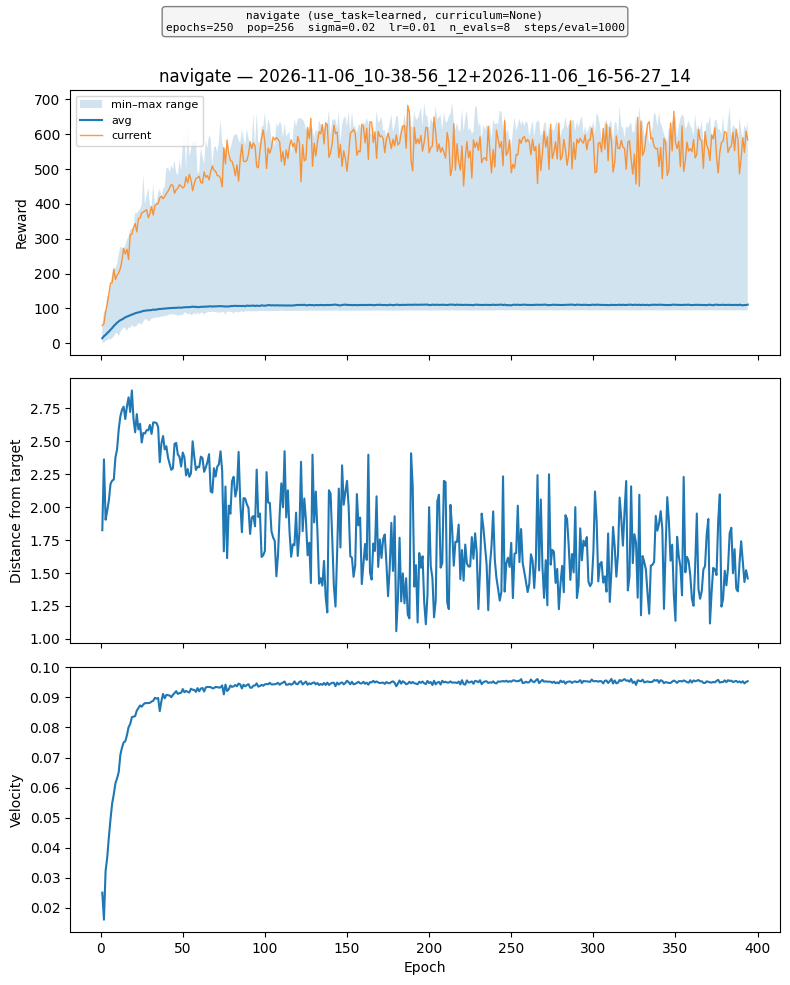

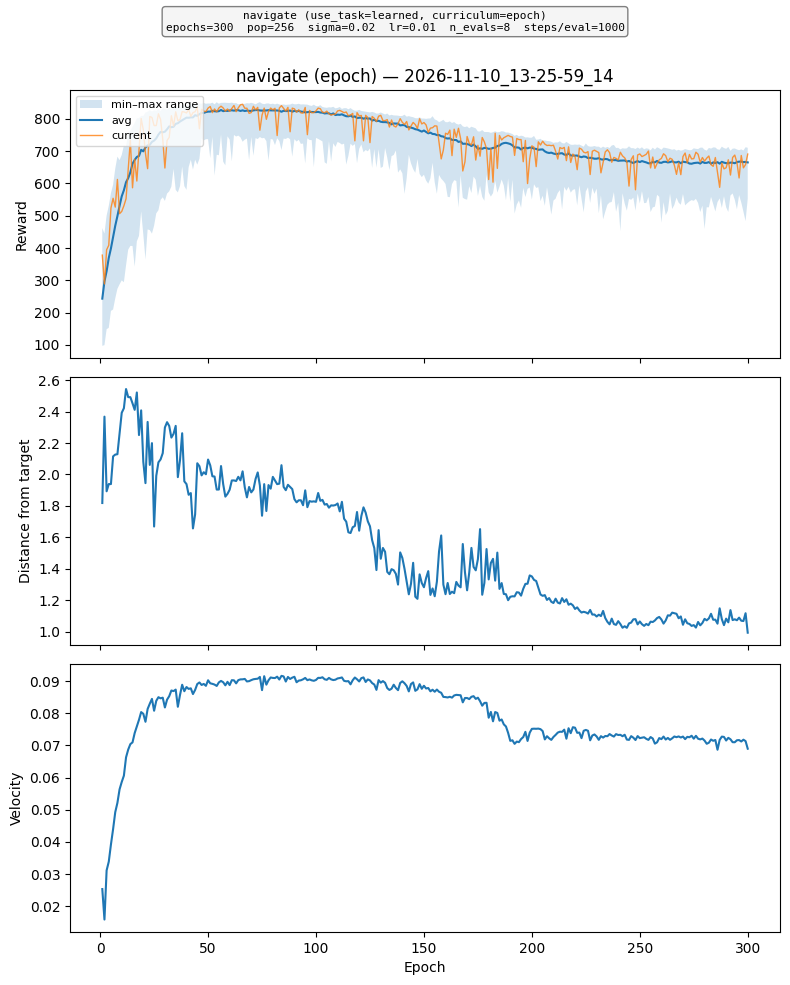

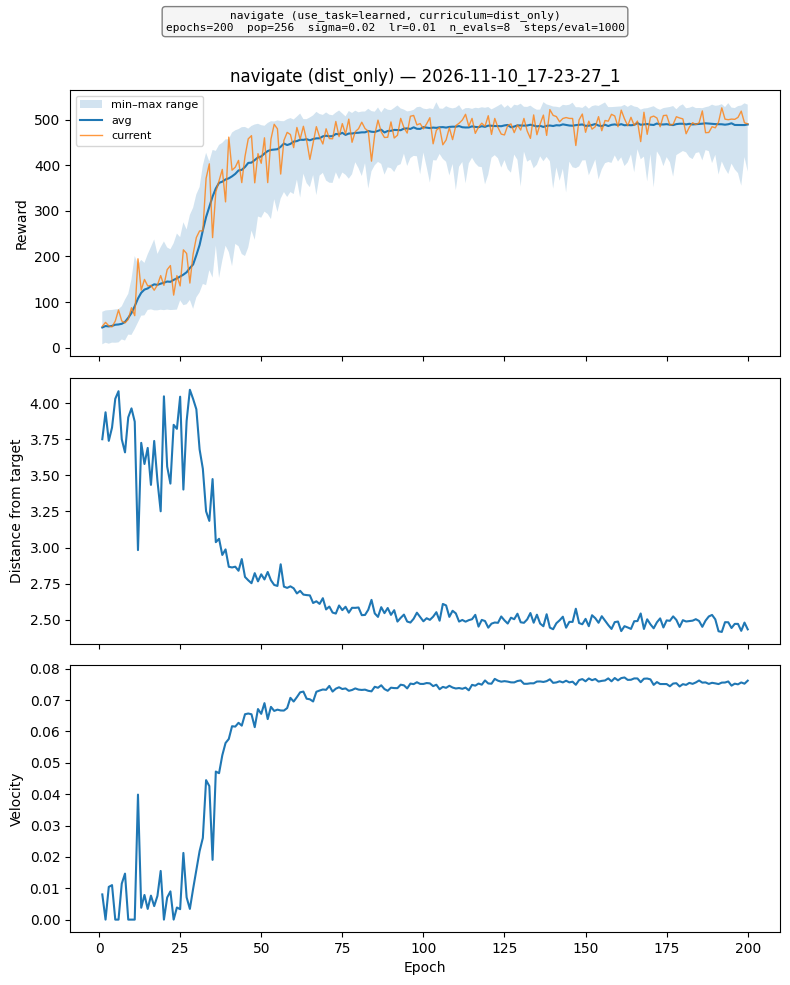

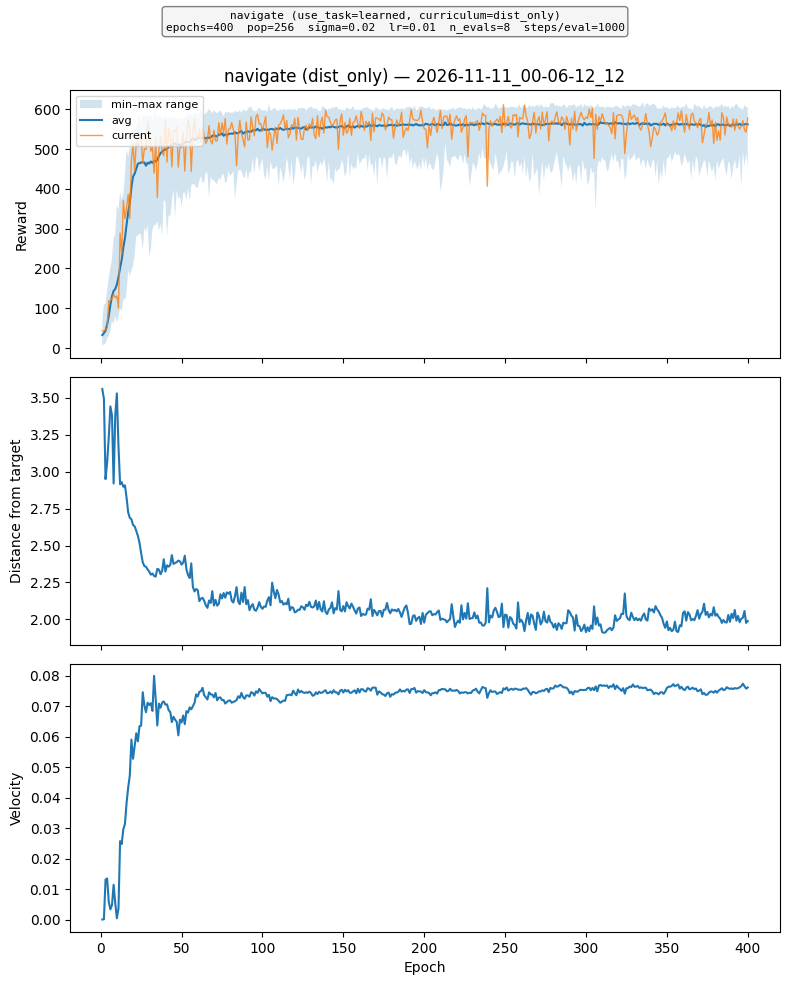

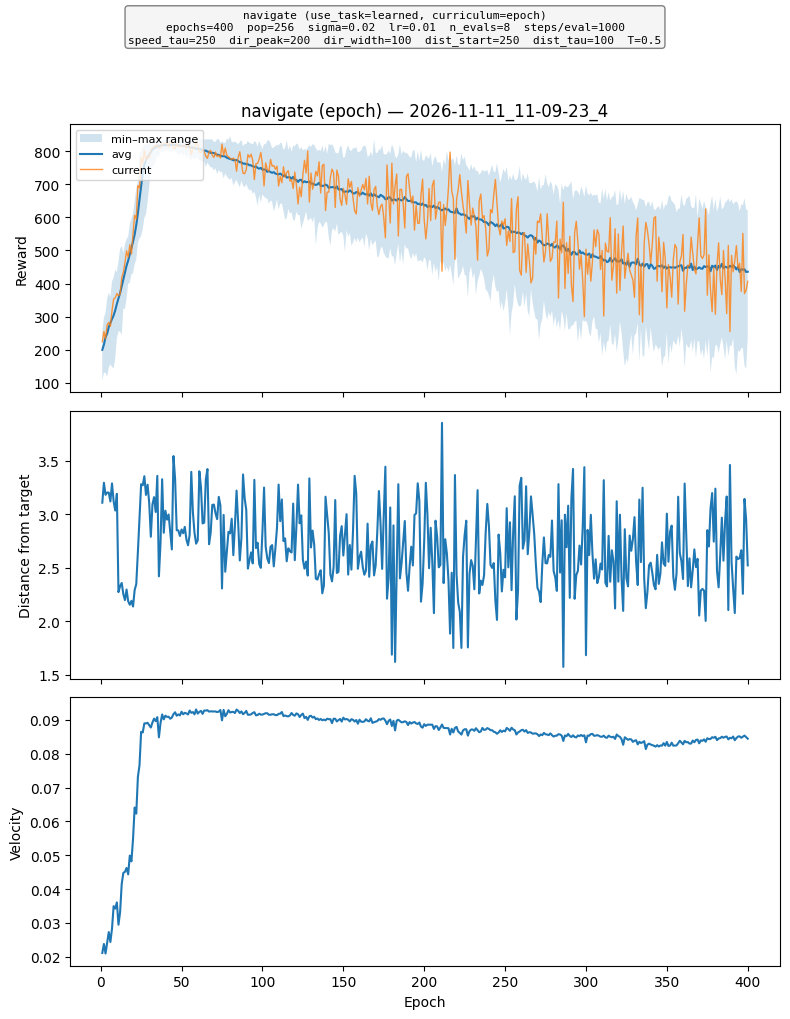

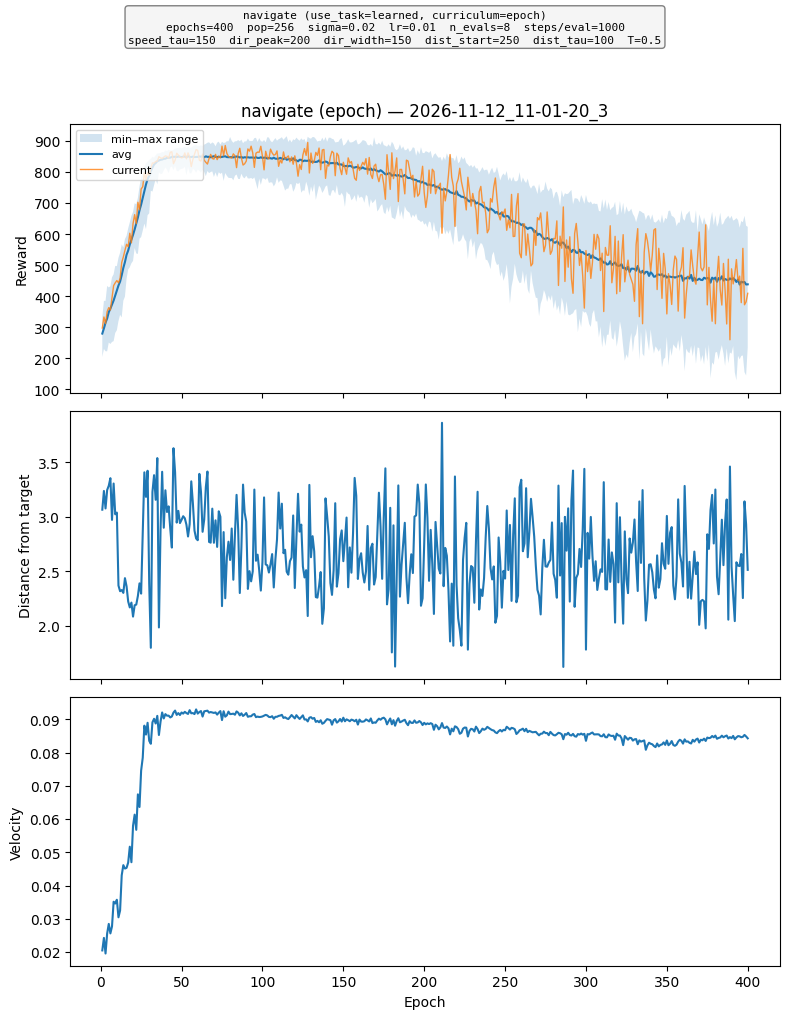

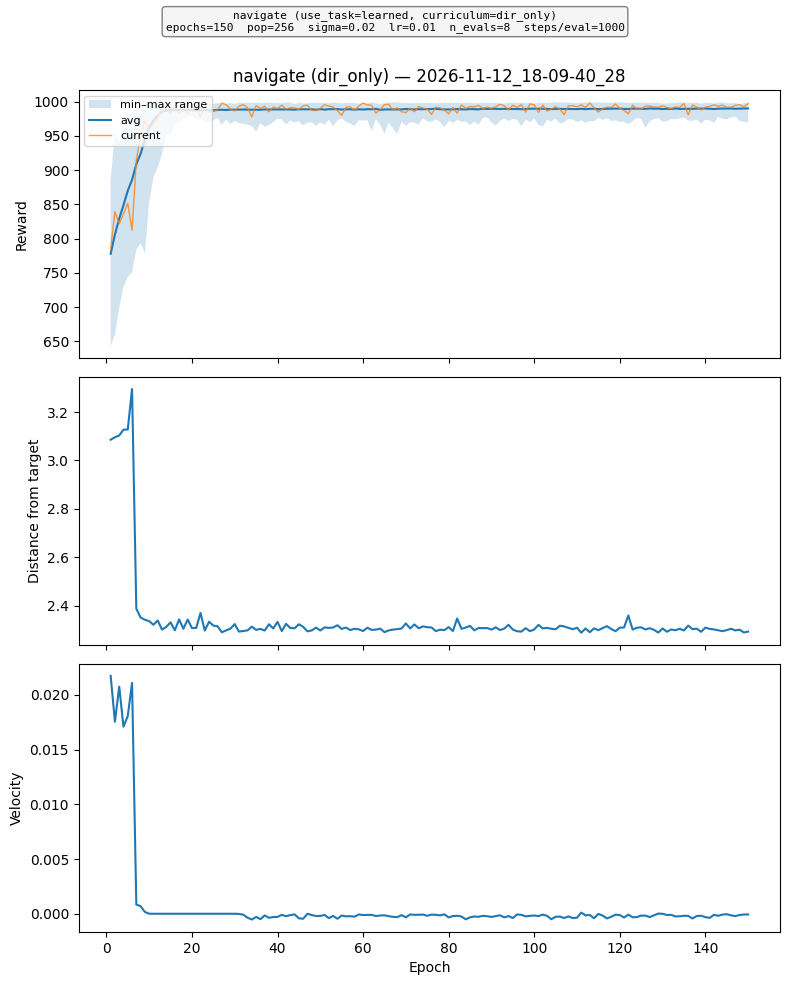

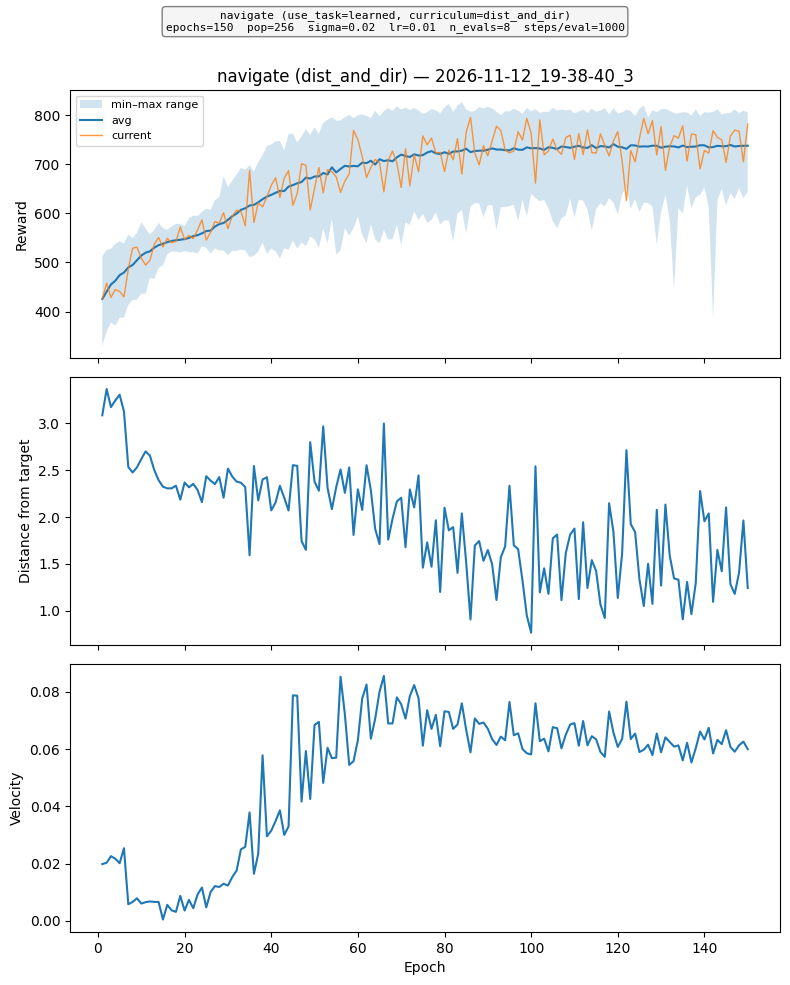

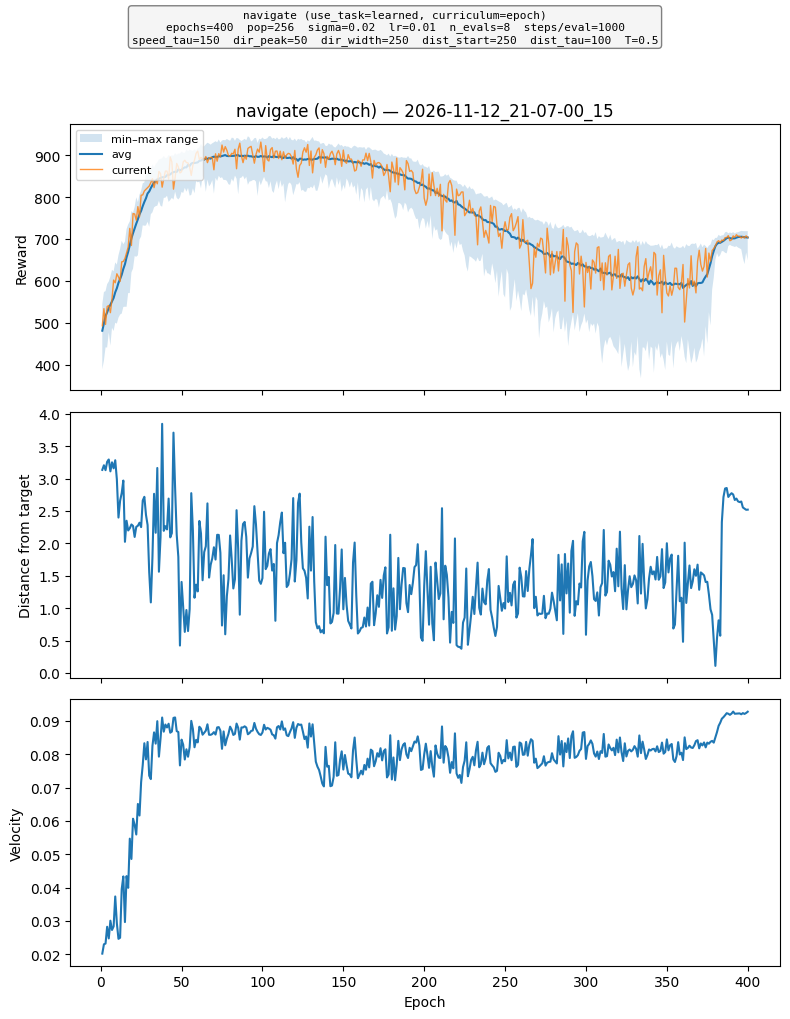

In [2]:
dir = r"D:\ncap-swimmer\FromGPUSERVER"

# 2026-11-05_19-01-48_27 and 2026-11-06_16-56-27_14 are the same training
# session (the second is a warm-started continuation of the first), so
# combine them into one continuous plot. 2026-11-09_19-58-51_29 is a
# separate, standalone run.
combined_runs = ["2026-11-06_10-38-56_12", "2026-11-06_16-56-27_14"]
solo_runs = ["2026-11-10_13-25-59_14", "2026-11-10_17-23-27_1", "2026-11-11_00-06-12_12",\
    "2026-11-11_11-09-23_4", "2026-11-12_11-01-20_3", "2026-11-12_18-09-40_28", "2026-11-12_19-38-40_3", \
        "2026-11-12_21-07-00_15"]

combined_csvs = [os.path.join(dir, name, "progress.csv") for name in combined_runs]
try:
    run_info = extract_run_info(os.path.join(dir, combined_runs[-1]))
except Exception as e:
    print(f"Failed to extract run info from {combined_runs[-1]}: {e}")
    run_info = None
print(f"Plotting combined training progress for {combined_runs}...")
plot_training_progress(combined_csvs, run_info=run_info, save=True, save_dir=r"D:\ncap-swimmer")

for name in solo_runs:
    run_dir = os.path.join(dir, name)
    csv_path = os.path.join(run_dir, "progress.csv")
    try:
        run_info = extract_run_info(run_dir)
    except Exception as e:
        print(f"Failed to extract run info from {run_dir}: {e}")
        run_info = None
    print(f"Plotting training progress for {run_dir}...")
    plot_training_progress(csv_path, run_info=run_info, save=True, save_dir=r"D:\ncap-swimmer")

In [ ]:
sweep_csv = os.path.join(r"D:\ncap-swimmer\outputs\<run>", "sweep_results.csv")

plot_sweep_trajectories(sweep_csv, save=True, save_dir=r"D:\ncap-swimmer")
plot_sweep_timeseries(sweep_csv, save=True, save_dir=r"D:\ncap-swimmer")
plot_sweep_final_distance(sweep_csv, save=True, save_dir=r"D:\ncap-swimmer")  # navigate sweeps only

In [5]:
widgets.interact(
    plot_reward_weight_schedule,
    n_epochs=widgets.IntSlider(min=50, max=600, step=10, value=300, description='n_epochs'),
    speed_tau=widgets.IntSlider(min=5, max=300, step=5, value=40, description='speed_tau'),
    dir_peak_epoch=widgets.IntSlider(min=0, max=600, step=10, value=90, description='dir_peak_epoch'),
    dir_width=widgets.IntSlider(min=5, max=300, step=5, value=40, description='dir_width'),
    dist_start_epoch=widgets.IntSlider(min=0, max=600, step=10, value=160, description='dist_start_epoch'),
    dist_tau=widgets.IntSlider(min=5, max=300, step=5, value=60, description='dist_tau'),
    temperature=widgets.FloatSlider(min=0.1, max=2.0, step=0.1, value=0.5, description='temperature'),
);

interactive(children=(IntSlider(value=300, description='n_epochs', max=600, min=50, step=10), IntSlider(value=…

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': 'target (-3.0, 0.0)'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': 'target (0.0, 2.0)'}, xlabel='x', ylabel='y'>],
       dtype=object),
        itr       target  step         x         y  velocity    reward  \
 0       10  (-3.0, 0.0)     0  0.027948 -0.048294       NaN       NaN   
 1       10  (-3.0, 0.0)     1  0.028061 -0.047780 -0.008561  0.144181   
 2       10  (-3.0, 0.0)     2  0.028404 -0.046495 -0.015295  0.144209   
 3       10  (-3.0, 0.0)     3  0.028984 -0.044789 -0.019568  0.144196   
 4       10  (-3.0, 0.0)     4  0.029773 -0.042911 -0.021655  0.144116   
 ...    ...          ...   ...       ...       ...       ...       ...   
 10005  300   (0.0, 2.0)   996 -0.156587  1.118278 -0.002294  0.148605   
 10006  300   (0.0, 2.0)   997 -0.155407  1.117964 -0.009577  0.148696   
 10007  300   (0.0, 2.0)   998 -0.154213  1.117372 -0.015062  0.148700   
 10008  300   (0.0, 2.0)   999 -0.153012 

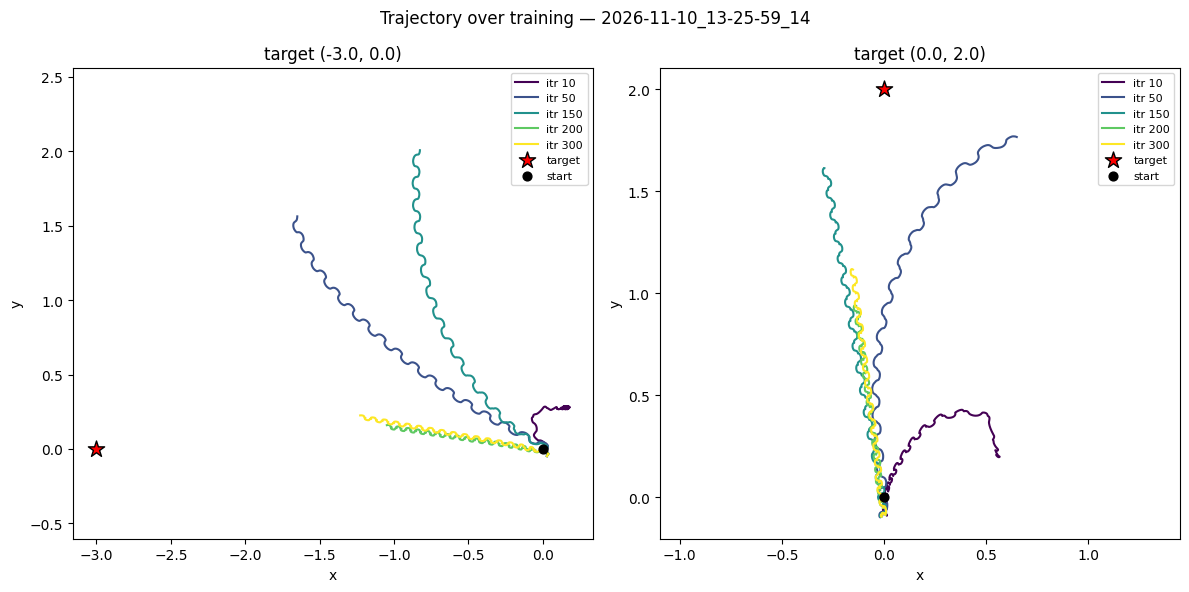

In [4]:
checkpoint_csv = os.path.join(
    r"D:\ncap-swimmer\FromGPUSERVER", "2026-11-10_13-25-59_14", "checkpoint_trajectories_10-50-150-200-300_seed1.csv")

plot_trajectory_over_checkpoints(checkpoint_csv, save_dir=r"D:\ncap-swimmer")

(<Figure size 1200x400 with 2 Axes>,
 array([<Axes: title={'center': 'target (-3.0, 0.0)'}, xlabel='Step', ylabel='Bearing (deg)'>,
        <Axes: title={'center': 'target (0.0, 2.0)'}, xlabel='Step', ylabel='Bearing (deg)'>],
       dtype=object),
        itr       target  step         x         y  velocity    reward  \
 0       10  (-3.0, 0.0)     0  0.024698 -0.063191       NaN       NaN   
 1       10  (-3.0, 0.0)     1  0.025040 -0.062803 -0.007011  0.017384   
 2       10  (-3.0, 0.0)     2  0.025945 -0.061834 -0.012077  0.017216   
 3       10  (-3.0, 0.0)     3  0.027244 -0.060566 -0.014595  0.016964   
 4       10  (-3.0, 0.0)     4  0.028778 -0.059211 -0.014991  0.016653   
 ...    ...          ...   ...       ...       ...       ...       ...   
 10005  300   (0.0, 2.0)   996  0.641267  2.039587  0.087529  0.864948   
 10006  300   (0.0, 2.0)   997  0.643267  2.041408  0.080537  0.796185   
 10007  300   (0.0, 2.0)   998  0.645268  2.042940  0.074951  0.741179   
 10008  300

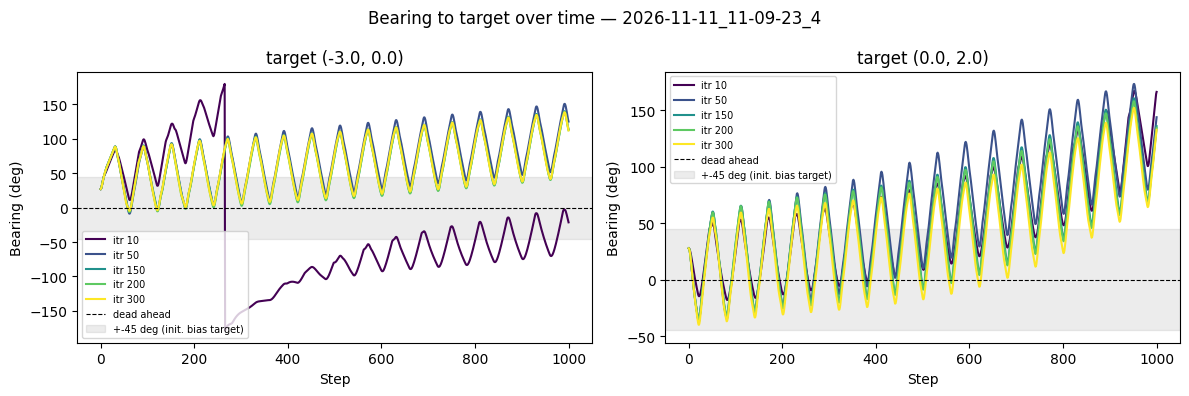

In [6]:
plot_bearing_over_time(checkpoint_csv, save_dir=r"D:\ncap-swimmer")

In [ ]:
run_dir = os.path.join(r"D:\ncap-swimmer\FromGPUSERVER", "2026-11-11_11-09-23_4")

seed_csvs = {
    1: os.path.join(run_dir, "checkpoint_trajectories_10-50-150-200-300.csv"),
    2: os.path.join(run_dir, "checkpoint_trajectories_10-50-150-200-300_seed2.csv"),
    5: os.path.join(run_dir, "checkpoint_trajectories_10-50-150-200-300_seed5.csv"),
}

for seed, csv_path in seed_csvs.items():
    df = load_checkpoint_trajectories(csv_path)
    step0 = df[df['step'] == 0]
    print(f"--- seed {seed} ---")
    for _, row in step0.iterrows():
        print(f"  itr={row['itr']} target={row['target']}: "
              f"bearing={np.degrees(row['bearing']):.1f} deg")

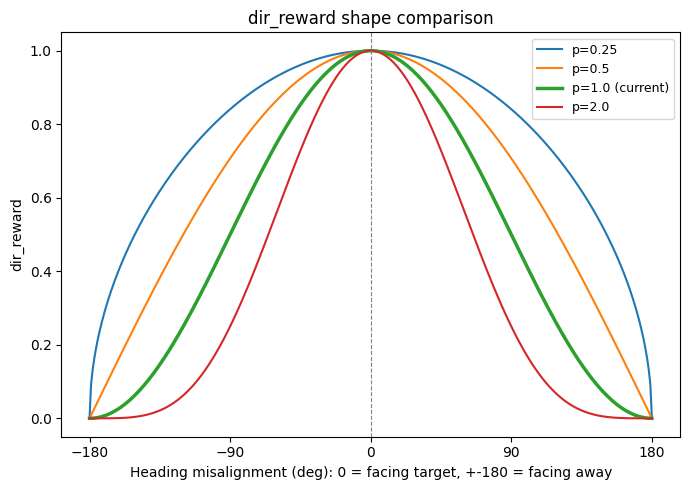

(<Figure size 700x500 with 1 Axes>,
 <Axes: title={'center': 'dir_reward shape comparison'}, xlabel='Heading misalignment (deg): 0 = facing target, +-180 = facing away', ylabel='dir_reward'>)

In [2]:
plot_dir_reward_shapes(ps=(0.25, 0.5, 1.0, 2.0), save_dir=r"D:\ncap-swimmer")